<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS09/lab1_js09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 – Install Library ANNOY
Jalankan sel berikut untuk memasang library `annoy`. Jika library sudah tersedia, instalasi dapat dilewati.

In [1]:
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 8.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520037 sha256=443bb9a122d9d08fcde565dc816cc199a8beb3c683123859a97cc94284b78c4b
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


## Langkah 2 – Import Library
NumPy digunakan untuk pengolahan data dan perhitungan jarak, Matplotlib untuk visualisasi, `time` untuk mengukur waktu komputasi, serta `AnnoyIndex` untuk menjalankan algoritma ANNOY.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

## Langkah 3 – Membuat Dataset Dummy
Dataset berisi 1.000 titik dengan dua koordinat (x dan y). `np.random.seed(42)` digunakan agar data acak dapat direproduksi. Query point dipilih secara acak dari salah satu titik pada dataset.

In [3]:
# Build Random Dataset and Query Point
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # random value at 100x100 space

# Query point (pick 1 random data point)
query = X[np.random.randint(0, n_points)]

print('Jumlah data:', len(X))
print('Dimensi data:', X.shape[1])
print('Query point:', query)

Jumlah data: 1000
Dimensi data: 2
Query point: [70.62422272  8.13487806]


## Langkah 4 – Exact Nearest Neighbor (Brute Force)
Metode Exact NN menghitung jarak query point ke seluruh titik data. Kemudian, `np.argsort()` mengurutkan jarak dari yang terkecil dan mengambil tiga indeks dengan jarak paling dekat.

Karena query dipilih dari dataset, salah satu tetangga terdekat adalah titik query itu sendiri dengan jarak 0.

In [4]:
# Compute Exact NN Using Brute Force
# It will visit the data one by one
start = time.perf_counter()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # ambil 3 terdekat
time_exact = time.perf_counter() - start

print('Exact NN index:', idx_exact)
print('Exact NN jarak:', distances[idx_exact])
print('Waktu Exact:', round(time_exact * 1000, 4), 'ms')

Exact NN index: [219 898 593]
Exact NN jarak: [0.         1.36915938 2.27931544]
Waktu Exact: 8.51 ms


## Langkah 5 – Approximate Nearest Neighbor dengan ANNOY
ANNOY membangun indeks berbasis beberapa tree untuk mempercepat pencarian. Pada percobaan ini digunakan dimensi 2, metrik Euclidean, dan 3 tree. Hasil pencarian kemudian dibandingkan dengan Exact NN.

In [5]:
# ANNOY 3 Tree
f = 2  # dimensi
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.perf_counter()
idx_ann = t.get_nns_by_vector(query, 3)  # find 3 NN
time_ann = time.perf_counter() - start

dist_ann = [np.linalg.norm(X[i] - query) for i in idx_ann]
print('Annoy NN index:', idx_ann)
print('Annoy NN jarak:', dist_ann)
print('Waktu Annoy:', round(time_ann * 1000, 4), 'ms')

Annoy NN index: [219, 898, 770]
Annoy NN jarak: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.568167959732514)]
Waktu Annoy: 0.124 ms


### Perbandingan Hasil
Tabel berikut merangkum indeks tetangga, jarak, dan waktu pencarian dari kedua metode. Perhatikan bahwa waktu yang diukur untuk ANNOY di sini adalah waktu pencarian setelah indeks selesai dibangun; waktu pembangunan tree tidak termasuk.

In [6]:
print('PERBANDINGAN EXACT NN DAN ANNOY')
print('-' * 55)
print(f'Exact NN : indeks={idx_exact.tolist()}, waktu={time_exact * 1000:.4f} ms')
print(f'ANNOY    : indeks={idx_ann}, waktu={time_ann * 1000:.4f} ms')
print('Indeks yang sama:', sorted(set(idx_exact.tolist()) & set(idx_ann)))

PERBANDINGAN EXACT NN DAN ANNOY
-------------------------------------------------------
Exact NN : indeks=[219, 898, 593], waktu=8.5100 ms
ANNOY    : indeks=[219, 898, 770], waktu=0.1240 ms
Indeks yang sama: [219, 898]


## Langkah 6 – Visualisasi Hasil NN
Grafik menampilkan seluruh titik dataset, query point, tiga tetangga terdekat hasil Exact NN, dan tiga hasil pencarian ANNOY. Titik yang terpilih oleh kedua metode dapat saling bertumpuk.

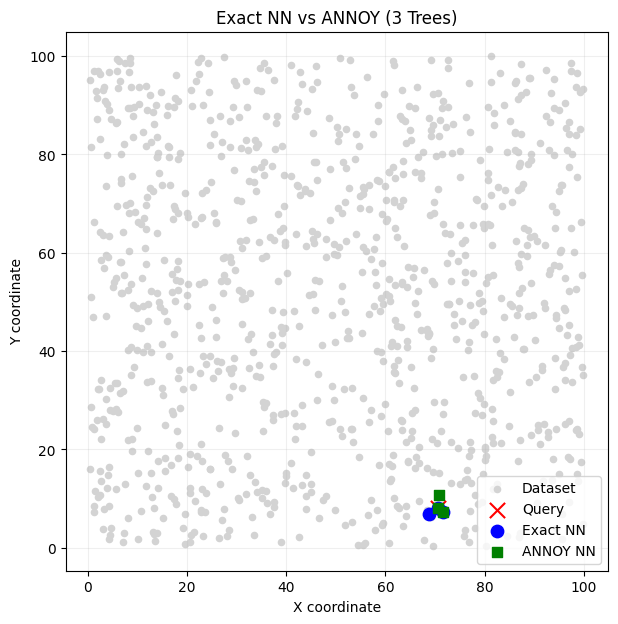

In [7]:
# Visualize Exact NN and ANNOY results
plt.figure(figsize=(7, 7))
plt.scatter(X[:, 0], X[:, 1], c='lightgray', s=20, label='Dataset')
plt.scatter(query[0], query[1], c='red', marker='x', s=120, label='Query')
plt.scatter(X[idx_exact, 0], X[idx_exact, 1], c='blue', s=80, label='Exact NN')
plt.scatter(X[idx_ann, 0], X[idx_ann, 1], c='green', s=55, marker='s', label='ANNOY NN')
plt.legend()
plt.title('Exact NN vs ANNOY (3 Trees)')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(alpha=0.2)
plt.show()

## Analisis dan Kesimpulan
1. **Exact NN** menghitung jarak terhadap seluruh data sehingga menghasilkan tetangga terdekat yang tepat berdasarkan metrik Euclidean.
2. **ANNOY** menggunakan struktur tree untuk mempercepat pencarian, tetapi hasilnya bersifat perkiraan sehingga tidak selalu sama dengan Exact NN.
3. Perbandingan waktu perlu memperhatikan bahwa pengukuran pada percobaan ini menghitung waktu pencarian saja pada ANNOY, tidak termasuk waktu membangun tree.
4. ANNOY cocok dipertimbangkan untuk dataset besar ketika kecepatan pencarian penting dan sedikit kompromi akurasi dapat diterima.

**Kesimpulan:** Praktikum menunjukkan trade-off antara ketepatan dan kecepatan. Exact NN mengutamakan hasil yang tepat, sedangkan ANNOY berupaya memperoleh hasil yang mendekati tepat dengan waktu pencarian lebih singkat.